## Dataset

In [ ]:
from sklearn.datasets import load_iris
import pandas as pd

# Load dataset as a Pandas DataFrame
iris = load_iris(as_frame=True)
df = iris.frame

# Display the first 5 rows to inspect the features
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## Iris Classification

=== 1. Loading Both Datasets (IRIS & Synthetic Make_Classification) ===

 PROCESSING DATASET: IRIS Dataset (Real)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(



--- Benchmark Summary Table (IRIS Dataset (Real)) ---
           Algorithm  Accuracy  Precision   Recall  F1-Score  ROC-AUC
           SVM (RBF)  0.966667   0.969697 0.966667  0.966583 0.996667
      SGD Classifier  0.966667   0.969697 0.966667  0.966583 0.966667
MLP (Neural Network)  0.966667   0.969697 0.966667  0.966583 0.996667
         Naive Bayes  0.966667   0.969697 0.966667  0.966583 0.990000
 Logistic Regression  0.933333   0.933333 0.933333  0.933333 0.996667
       Decision Tree  0.933333   0.933333 0.933333  0.933333 0.973333
           KNN (k=5)  0.933333   0.944444 0.933333  0.932660 0.993333
          Perceptron  0.866667   0.875000 0.866667  0.865320      NaN


/tmp/ipykernel_1528/2698011680.py:117: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_benchmark, x='F1-Score', y='Algorithm', palette=colors, ax=axes[0])


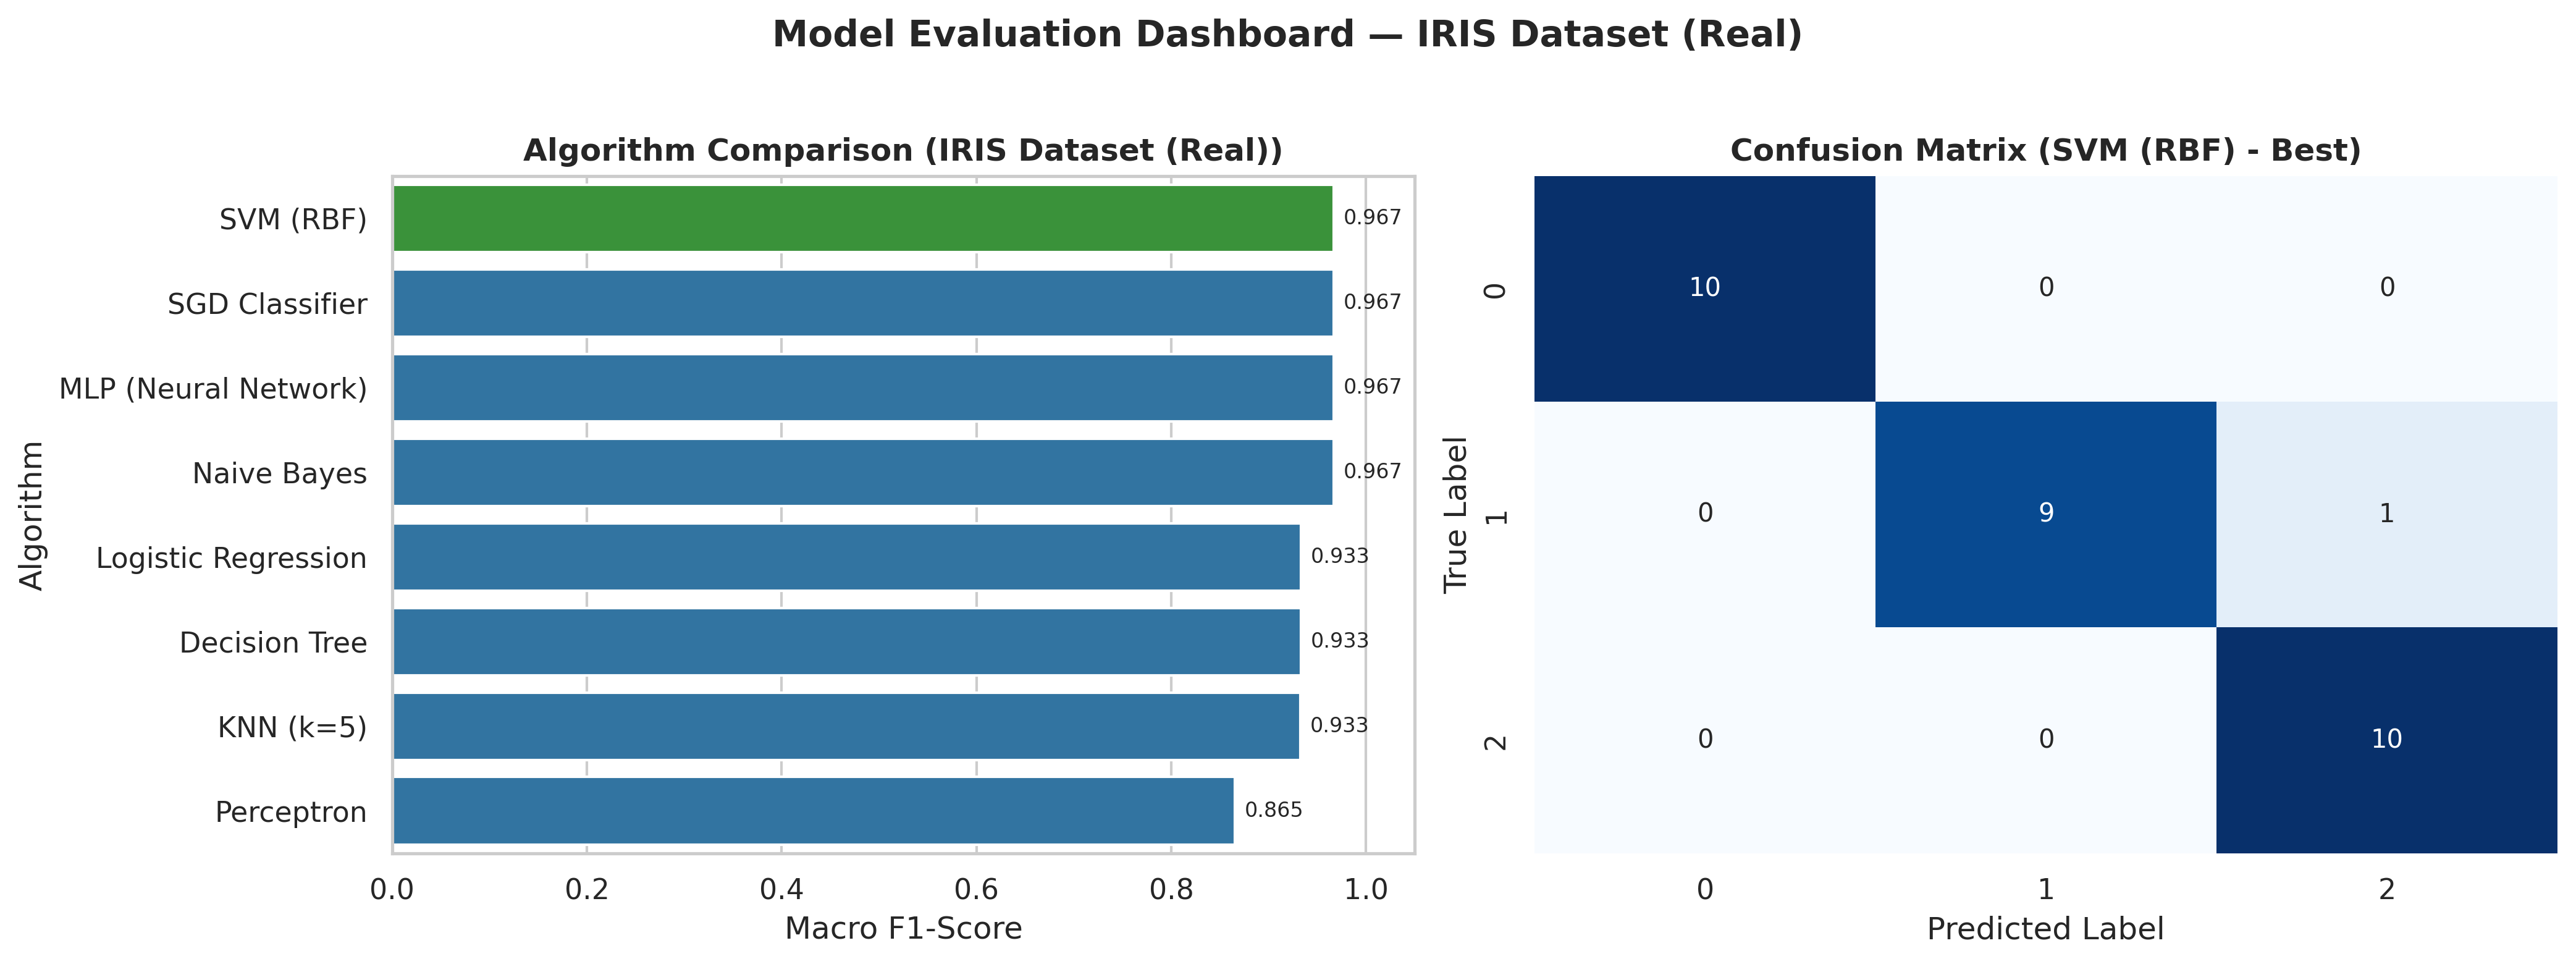


 PROCESSING DATASET: Synthetic Dataset (make_classification)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/tmp/ipykernel_1528/2698011680.py:117: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_benchmark, x='F1-Score', y='Algorithm', palette=colors, ax=axes[0])



--- Benchmark Summary Table (Synthetic Dataset (make_classification)) ---
           Algorithm  Accuracy  Precision   Recall  F1-Score  ROC-AUC
           SVM (RBF)  0.816667   0.821535 0.816667  0.816534 0.931250
           KNN (k=5)  0.816667   0.824819 0.816667  0.816502 0.901250
MLP (Neural Network)  0.816667   0.820813 0.816667  0.816147 0.942917
       Decision Tree  0.766667   0.787785 0.766667  0.766530 0.847500
 Logistic Regression  0.700000   0.698622 0.700000  0.699031 0.833750
         Naive Bayes  0.700000   0.698611 0.700000  0.694613 0.833333
          Perceptron  0.533333   0.526455 0.533333  0.520554      NaN
      SGD Classifier  0.450000   0.626126 0.450000  0.417366 0.703750


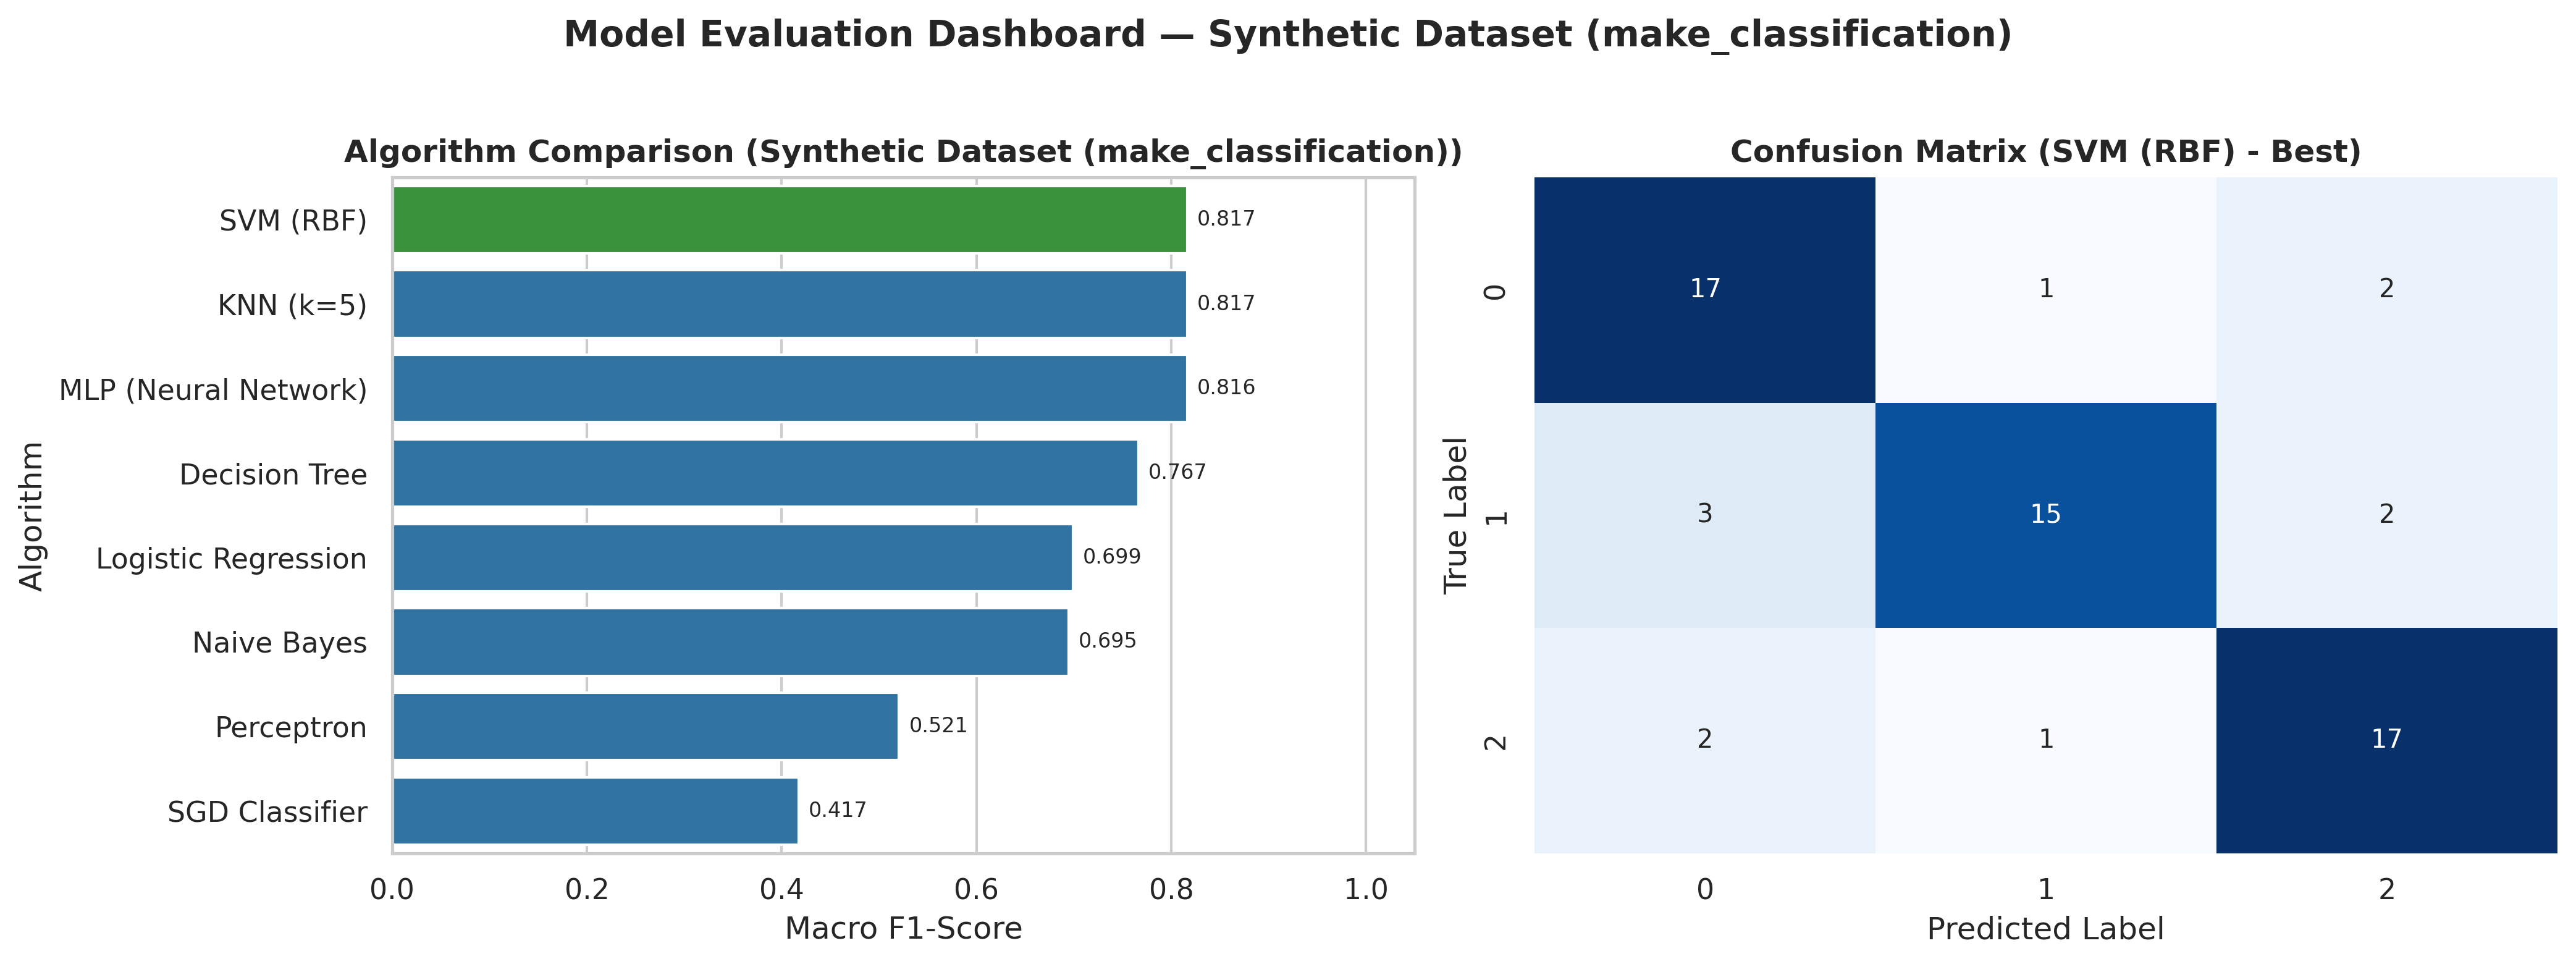


=== 4. Advanced Hyperparameter Tuning (Decision Tree on IRIS) ===
 > Best Hyperparameters Found : {'criterion': 'gini', 'max_depth': 6, 'max_features': None, 'splitter': 'best'}
 > Best CV Macro F1-Score     : 0.8071


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, make_classification
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# Algorithms
from sklearn.linear_model import LogisticRegression, Perceptron, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

# Set global plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10, 'figure.dpi': 300})

print("=== 1. Loading Both Datasets (IRIS & Synthetic Make_Classification) ===")
# 1. Real Dataset: IRIS Dataset
X_iris, y_iris = load_iris(return_X_y=True)

# 2. Synthetic Dataset: make_classification
X_syn, y_syn = make_classification(
    n_samples=300, n_features=6, n_classes=3,
    n_informative=3, n_redundant=1, random_state=42
)

# Dictionary holding both datasets for multi-dataset evaluation
datasets = {
    "IRIS Dataset (Real)": (X_iris, y_iris),
    "Synthetic Dataset (make_classification)": (X_syn, y_syn)
}

# Iterate over each dataset to train, evaluate, and compare
for ds_name, (X, y) in datasets.items():
    print(f"\n{'='*50}")
    print(f" PROCESSING DATASET: {ds_name}")
    print(f"{'='*50}")

    # Stratified Train-Test Split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Feature Scaling (Crucial for distance/gradient/kernel-based models)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Define Classifiers with Specified Parameters & Solvers
    classifiers = {
        "Logistic Regression": LogisticRegression(solver='lbfgs', random_state=42),
        "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
        "Decision Tree": DecisionTreeClassifier(criterion='gini', splitter='best', max_depth=4, random_state=42),
        "SVM (RBF)": SVC(kernel='rbf', C=1.0, probability=True, random_state=42),
        "Naive Bayes": GaussianNB(),
        "Perceptron": Perceptron(random_state=42),
        "MLP (Neural Network)": MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=500, random_state=42),
        "SGD Classifier": SGDClassifier(loss='log_loss', random_state=42)
    }

    evaluation_results = []
    predictions_dict = {}

    for name, clf in classifiers.items():
        # Assign scaled vs unscaled features depending on model requirements
        is_scaled_model = name in ["KNN (k=5)", "SVM (RBF)", "Perceptron", "MLP (Neural Network)", "SGD Classifier", "Logistic Regression"]
        X_tr = X_train_scaled if is_scaled_model else X_train
        X_te = X_test_scaled if is_scaled_model else X_test

        # Train model
        clf.fit(X_tr, y_train)
        y_pred = clf.predict(X_te)
        y_proba = clf.predict_proba(X_te) if hasattr(clf, "predict_proba") else None

        # Comprehensive Evaluation Metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
        rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
        f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

        try:
            auc = roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro') if y_proba is not None else np.nan
        except:
            auc = np.nan

        evaluation_results.append({
            "Algorithm": name,
            "Accuracy": acc,
            "Precision": prec,
            "Recall": rec,
            "F1-Score": f1,
            "ROC-AUC": auc
        })
        predictions_dict[name] = y_pred

    df_benchmark = pd.DataFrame(evaluation_results).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
    print(f"\n--- Benchmark Summary Table ({ds_name}) ---")
    print(df_benchmark.to_string(index=False))

    # Identify best performing model for confusion matrix plotting
    best_model_name = df_benchmark.iloc[0]['Algorithm']

    # Visual Comparison Dashboard for current dataset
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Panel 1: Bar Chart of F1-Scores
    colors = ['#2ca02c' if name == best_model_name else '#1f77b4' for name in df_benchmark['Algorithm']]
    sns.barplot(data=df_benchmark, x='F1-Score', y='Algorithm', palette=colors, ax=axes[0])
    axes[0].set_title(f"Algorithm Comparison ({ds_name})", fontweight='bold')
    axes[0].set_xlabel("Macro F1-Score")
    axes[0].set_xlim(0, 1.05)
    for i, v in enumerate(df_benchmark['F1-Score']):
        axes[0].text(v + 0.01, i, f"{v:.3f}", va='center', fontsize=8)

    # Panel 2: Confusion Matrix of Best Model
    best_preds = predictions_dict[best_model_name]
    cm = confusion_matrix(y_test, best_preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1])
    axes[1].set_title(f"Confusion Matrix ({best_model_name} - Best)", fontweight='bold')
    axes[1].set_xlabel("Predicted Label")
    axes[1].set_ylabel("True Label")

    plt.suptitle(f"Model Evaluation Dashboard — {ds_name}", fontsize=14, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()

# ==========================================
# 4. HYPERPARAMETER TUNING (GridSearchCV)
# ==========================================
print("\n=== 4. Advanced Hyperparameter Tuning (Decision Tree on IRIS) ===")
dt_param_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'splitter': ['best', 'random'],
    'max_depth': [2, 4, 6, 8, None],
    'max_features': ['sqrt', 'log2', None]
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_macro',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)
print(f" > Best Hyperparameters Found : {dt_grid.best_params_}")
print(f" > Best CV Macro F1-Score     : {dt_grid.best_score_:.4f}")

## Robust Regression

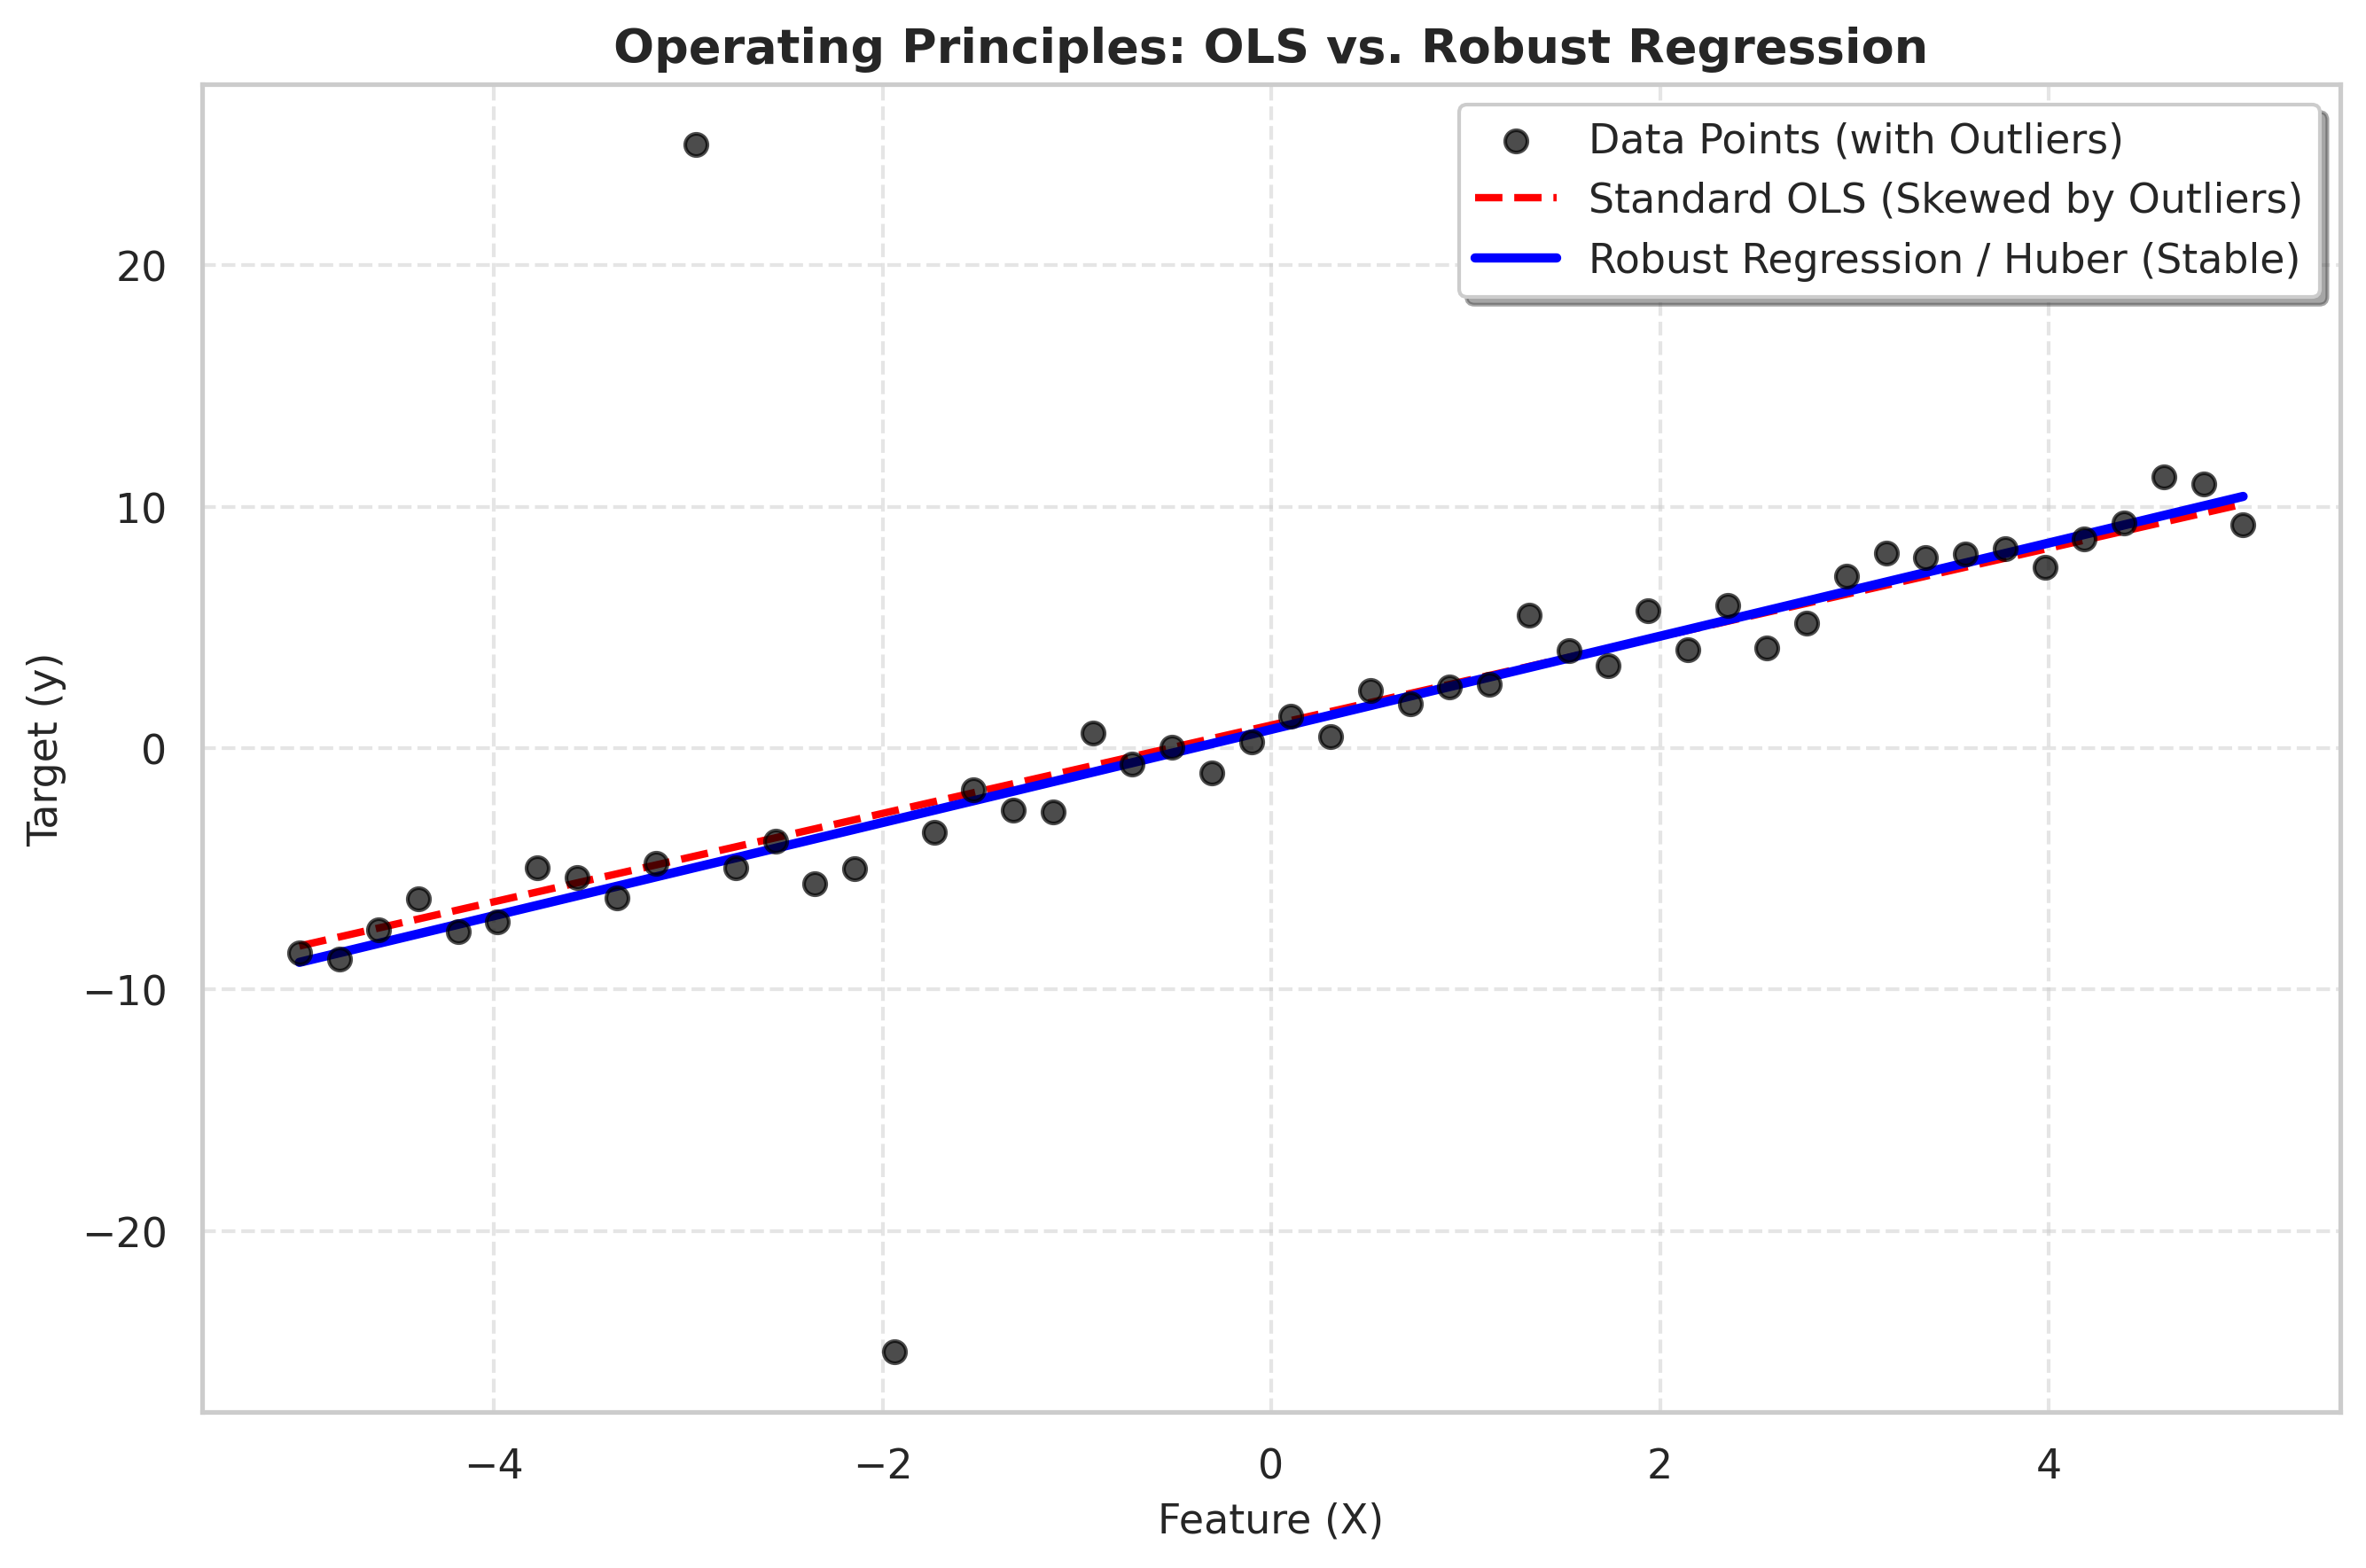

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, HuberRegressor

# 1. Generate clean base data
np.random.seed(42)
X = np.linspace(-5, 5, 50)
y = 2 * X + 1 + np.random.normal(0, 1, size=X.shape)

# 2. Artificially introduce extreme outliers
y_outliers = y.copy()
y_outliers[10] = 25   # Upper outlier
y_outliers[15] = -25  # Lower outlier

X_reshaped = X.reshape(-1, 1)

# 3. Train Standard OLS vs. Robust Regression (Huber)
ols = LinearRegression()
ols.fit(X_reshaped, y_outliers)

huber = HuberRegressor(epsilon=1.35)
huber.fit(X_reshaped, y_outliers)

# 4. Plotting the results
plt.figure(figsize=(9, 6))
plt.scatter(X, y_outliers, color='black', label='Data Points (with Outliers)', alpha=0.7, zorder=3)
plt.plot(X, ols.predict(X_reshaped), color='red', linestyle='--', linewidth=2, label='Standard OLS (Skewed by Outliers)')
plt.plot(X, huber.predict(X_reshaped), color='blue', linewidth=2.5, label='Robust Regression / Huber (Stable)')

plt.xlabel('Feature (X)', fontsize=11)
plt.ylabel('Target (y)', fontsize=11)
plt.title('Operating Principles: OLS vs. Robust Regression', fontsize=13, fontweight='bold')
plt.legend(frameon=True, facecolor='white', shadow=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()